# Đồ thị 06 Scatter giữa EF và serum creatinine

**Võ Minh Huy — 2311110117**

Vẽ cặp chỉ số ejection_fraction và serum_creatinine, tô màu và dùng hình điểm khác nhau theo DEATH_EVENT. Chỉ dùng 298 hồ sơ có nhãn hợp lệ: 203 nhãn 0 và 95 nhãn 1. Một hồ sơ chờ xác minh nhãn được giữ trong file after, không tham gia biểu đồ cần nhãn này.


In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])
    import matplotlib.pyplot as plt

thu_muc = Path.cwd()
if thu_muc.name == "python":
    thu_muc = thu_muc.parent
du_lieu = pd.read_csv(thu_muc / "VoMinhHuy_Heart Failure Prediction_after_Python.csv")
for cot in ["ejection_fraction", "serum_creatinine", "DEATH_EVENT"]:
    du_lieu[cot] = pd.to_numeric(du_lieu[cot], errors="raise")
hop_le = du_lieu["DEATH_EVENT"].isin([0,1])
if (du_lieu["DEATH_EVENT"].notna() & ~hop_le).any():
    raise ValueError("Còn nhãn ngoài miền 0/1; cần kiểm tra file after.")
du_lieu_ve = du_lieu.loc[hop_le, ["MaHoSo", "ejection_fraction", "serum_creatinine", "DEATH_EVENT"]].copy()
if du_lieu_ve[["ejection_fraction","serum_creatinine"]].isna().any().any():
    raise ValueError("Hai chỉ số cần đủ giá trị trước khi vẽ.")
assert len(du_lieu) == 299 and len(du_lieu_ve) == 298
assert np.isfinite(du_lieu_ve[["ejection_fraction","serum_creatinine"]]).all().all()
assert du_lieu_ve["ejection_fraction"].between(0,100).all()
assert (du_lieu_ve["serum_creatinine"] > 0).all()
assert du_lieu_ve["DEATH_EVENT"].value_counts().to_dict() == {0.0:203, 1.0:95}
du_lieu_ve["DEATH_EVENT"] = du_lieu_ve["DEATH_EVENT"].astype(int)
thu_muc_kq = thu_muc / "ket_qua/21_do_thi/06_scatter_ef_creatinine"
thu_muc_kq.mkdir(parents=True, exist_ok=True)
quy_mo = pd.DataFrame({"SoHoSoAfter":[len(du_lieu)], "SoHoSoVe":[len(du_lieu_ve)],
    "Nhan0":[int((du_lieu_ve["DEATH_EVENT"]==0).sum())],
    "Nhan1":[int((du_lieu_ve["DEATH_EVENT"]==1).sum())],
    "NhanChoXacMinhKhongVe":[int(du_lieu["DEATH_EVENT"].isna().sum())]})
quy_mo


,SoHoSoAfter,SoHoSoVe,Nhan0,Nhan1,NhanChoXacMinhKhongVe
0,299,298,203,95,1


In [2]:
# Bảng mô tả hỗ trợ đọc đồ thị, không phải kết quả dự đoán.
dong_thong_ke = []
for nhan, nhom in du_lieu_ve.groupby("DEATH_EVENT", sort=True):
    dong_thong_ke.append({"DEATH_EVENT":nhan, "SoHoSo":len(nhom),
        "EFMean":nhom["ejection_fraction"].mean(),
        "EFMedian":nhom["ejection_fraction"].median(),
        "CreatinineMean":nhom["serum_creatinine"].mean(),
        "CreatinineMedian":nhom["serum_creatinine"].median()})
thong_ke = pd.DataFrame(dong_thong_ke)
thong_ke.round(2)


,DEATH_EVENT,SoHoSo,EFMean,EFMedian,CreatinineMean,CreatinineMedian
0,0,203,40.27,38.0,1.20,1.1
1,1,95,33.56,30.0,1.85,1.3


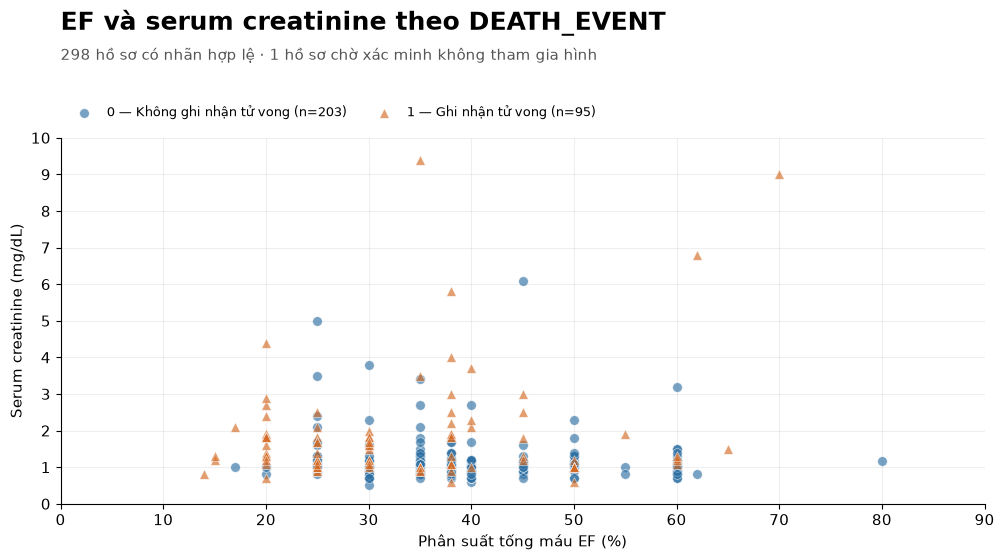

In [3]:
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11})
fig, ax = plt.subplots(figsize=(10.5,6))
fig.subplots_adjust(top=0.76,bottom=0.15,left=0.10,right=0.98)
fig.text(0.10,0.94,"EF và serum creatinine theo DEATH_EVENT",fontsize=18,weight="bold")
fig.text(0.10,0.89,"298 hồ sơ có nhãn hợp lệ · 1 hồ sơ chờ xác minh không tham gia hình",color="#555555")
for nhan, mau, ky_hieu, mo_ta in [(0,"#2E70A3","o","Không ghi nhận tử vong"),
    (1,"#D46A24","^","Ghi nhận tử vong")]:
    nhom = du_lieu_ve.loc[du_lieu_ve["DEATH_EVENT"].eq(nhan)]
    ax.scatter(nhom["ejection_fraction"],nhom["serum_creatinine"],
        color=mau,marker=ky_hieu,s=48,alpha=0.65,edgecolors="white",linewidths=0.5,
        label=f"{nhan} — {mo_ta} (n={len(nhom)})")
assert sum(len(c.get_offsets()) for c in ax.collections) == len(du_lieu_ve)
ax.set(xlabel="Phân suất tống máu EF (%)",ylabel="Serum creatinine (mg/dL)",
    xlim=(0,90),ylim=(0,10))
ax.set_xticks(np.arange(0,91,10))
ax.set_yticks(np.arange(0,11,1))
ax.grid(alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top","right"]].set_visible(False)
ax.legend(frameon=False,loc="lower left",bbox_to_anchor=(0,1.02),ncol=2,fontsize=9)
fig.savefig(thu_muc_kq / "06_scatter_ef_creatinine.png",dpi=300,bbox_inches="tight",facecolor="white")
quy_mo.to_csv(thu_muc_kq / "quy_mo_python.csv",index=False,encoding="utf-8-sig")
thong_ke.to_csv(thu_muc_kq / "thong_ke_nhan_python.csv",index=False,encoding="utf-8-sig")
du_lieu_ve.to_csv(thu_muc_kq / "du_lieu_ve_python.csv",index=False,encoding="utf-8-sig")
plt.show()


## Nhận xét

Hai nhóm nhãn có vùng điểm chồng lấn; riêng hai chỉ số này không tạo ranh giới phân loại rõ ràng trên hình. Dùng bảng mô tả để so sánh mean và median của từng nhóm, không suy ra quan hệ nhân quả hoặc hiệu quả dự đoán từ đồ thị.

Mỗi hồ sơ được đưa vào lệnh vẽ đúng một lần. Các điểm trùng tọa độ có thể chồng lên nhau; độ trong suốt giúp quan sát nhưng số chấm nhìn thấy có thể nhỏ hơn 298. Không jitter, không cắt các giá trị creatinine cao. Nhãn ghi nhận kết quả trong thời gian theo dõi của dữ liệu; nhãn 0 không đồng nghĩa không có bệnh.

Các chỉ số đã qua tiền xử lý, có thể chứa giá trị đã điền ở N05 và N07. Giữ nguyên file after và hồ sơ chờ xác minh nhãn.
